# 第三轮：tau = t*rho，c_s 按定理取，rho 网格加宽；Waterbirds 正则项中心放在初始点

运行时选 A100，按顺序运行全部单元格；结果文件名带 `_r3`。


In [8]:
# 1. 检查算力与基础环境
import os, platform, subprocess, time, json, itertools, warnings
import numpy as np
import torch
import torch.nn.functional as F

warnings.filterwarnings("ignore")
print("Host:", platform.node(), "| Python:", platform.python_version(), "| CPUs:", os.cpu_count())
res = subprocess.run(["nvidia-smi", "--query-gpu=name,memory.total", "--format=csv,noheader"],
                     capture_output=True, text=True)
print("GPU:", res.stdout.strip() if res.returncode == 0 else "No GPU (CPU runtime)")

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
DTYPE = torch.float64  # float64 avoids 1e-6 precision floor for KKT residuals
print(f"PyTorch: {torch.__version__} | device={DEVICE} | dtype={DTYPE}")

Host: 433d5f1d5c19 | Python: 3.13.16 | CPUs: 12
GPU: NVIDIA A100-SXM4-80GB, 81920 MiB
PyTorch: 2.14.1+cu130 | device=cuda | dtype=torch.float64


In [9]:
# 2. 输出/缓存目录与全局实验参数
if os.path.isdir("/content"):  # Colab runtime (browser or IDE extension)
    DATA_DIR = "/content/data"
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        OUT_DIR = "/content/drive/MyDrive/3_DDLALM_exp"
    except Exception as e:
        print("Drive not mounted:", type(e).__name__)
        OUT_DIR = "/content/3_DDLALM_exp"
else:
    OUT_DIR = os.path.abspath("results")
    DATA_DIR = os.path.abspath("data")

os.makedirs(OUT_DIR, exist_ok=True)
os.makedirs(DATA_DIR, exist_ok=True)
print("OUT_DIR:", OUT_DIR, "| DATA_DIR:", DATA_DIR)

SEED = 0
WB_EPS = 1e-3        # Waterbirds Group DRO target KKT accuracy
WB_BUDGET = 4000     # oracle call budget for Waterbirds
MN_EPS = 1e-4        # MNIST mNPC target KKT accuracy
MN_BUDGET = 4000     # oracle call budget for MNIST mNPC
BATCH_SIZE = 128 if DEVICE.type == "cuda" else 16

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
OUT_DIR: /content/drive/MyDrive/3_DDLALM_exp | DATA_DIR: /content/data


In [10]:
# 3. 数据集自动下载与预处理缓存
import tarfile, urllib.request, csv, shutil
from PIL import Image
import torchvision
from torchvision import transforms, models
from torch.utils.data import Dataset, DataLoader

# WILDS mirror of Waterbirds (same metadata.csv: img_filename, y, place, split); nlp.stanford.edu is unreachable
WATERBIRDS_URL = "https://worksheets.codalab.org/rest/bundles/0x505056d5cdea4e4eaa0e242cbfe2daa4/contents/blob/"


class _ImageListDataset(Dataset):
    def __init__(self, root, filenames, tfm):
        self.root, self.filenames, self.tfm = root, filenames, tfm

    def __len__(self):
        return len(self.filenames)

    def __getitem__(self, idx):
        img = Image.open(os.path.join(self.root, self.filenames[idx])).convert("RGB")
        return self.tfm(img)


def load_waterbirds_features(cache_dir=OUT_DIR, data_dir=DATA_DIR, proj_dim=32):
    """Download Waterbirds (Sagawa et al. 2020), extract ImageNet-pretrained ResNet18
    features on the training split, project to R^{32} via fixed PCA, and cache."""
    cache_path = os.path.join(cache_dir, f"waterbirds_resnet18_{proj_dim}d.npz")
    if os.path.exists(cache_path):
        d = np.load(cache_path)
        print(f"[Waterbirds] Loaded cached features from {cache_path}: shape={d['A'].shape}")
        return d["A"], d["b"], d["groups"]

    wb_root = os.path.join(data_dir, "waterbird_complete95_forest2water2")
    tar_path = os.path.join(data_dir, "waterbird_complete95_forest2water2.tar.gz")
    if not os.path.exists(os.path.join(wb_root, "metadata.csv")):
        if os.path.exists(tar_path) and os.path.getsize(tar_path) < 10**6:
            os.remove(tar_path)  # drop an empty or partial download
        if not os.path.exists(tar_path):
            print("[Waterbirds] Downloading tarball from the WILDS CodaLab mirror...")
            if shutil.which("wget"):
                subprocess.run(["wget", "-q", "--show-progress", "-O", tar_path, WATERBIRDS_URL], check=True)
            else:
                urllib.request.urlretrieve(WATERBIRDS_URL, tar_path)
        print("[Waterbirds] Extracting tarball...")
        os.makedirs(wb_root, exist_ok=True)
        with tarfile.open(tar_path, "r:gz") as tf:
            tf.extractall(wb_root)  # the WILDS tarball has no top-level folder

    filenames, labels, groups = [], [], []
    with open(os.path.join(wb_root, "metadata.csv"), "r") as f:
        for row in csv.DictReader(f):
            if int(row["split"]) == 0:  # official training split (4795 images)
                y = int(row["y"])
                place = int(row["place"])
                filenames.append(row["img_filename"])
                labels.append(1.0 if y == 1 else -1.0)
                groups.append(2 * y + place)

    tfm = transforms.Compose([
        transforms.Resize(256),
        transforms.CenterCrop(224),
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
    ])
    ds = _ImageListDataset(wb_root, filenames, tfm)
    loader = DataLoader(ds, batch_size=256, shuffle=False, num_workers=min(4, os.cpu_count() or 2),
                        pin_memory=(DEVICE.type == "cuda"))

    print(f"[Waterbirds] Extracting ResNet18 features for {len(ds)} images on {DEVICE}...")
    t0 = time.time()
    backbone = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
    backbone.fc = torch.nn.Identity()
    backbone = backbone.to(DEVICE).eval()
    feats = []
    with torch.no_grad():
        for xb in loader:
            feats.append(backbone(xb.to(DEVICE, non_blocking=True)).cpu().numpy())
    X512 = np.concatenate(feats, axis=0).astype(np.float64)
    print(f"[Waterbirds] Feature extraction done in {time.time() - t0:.1f}s")

    # Fixed projection R^512 -> R^32 via top-32 PCA on centered training features, standardized
    X_centered = X512 - X512.mean(axis=0, keepdims=True)
    _, _, Vt = np.linalg.svd(X_centered, full_matrices=False)
    A = X_centered @ Vt[:proj_dim].T
    A = A / (np.std(A, axis=0, keepdims=True) + 1e-8) / np.sqrt(proj_dim)
    b = np.array(labels, dtype=np.float64)
    g = np.array(groups, dtype=np.int64)
    np.savez(cache_path, A=A, b=b, groups=g)
    print(f"[Waterbirds] Cached to {cache_path} | group counts={[int((g == k).sum()) for k in range(4)]}")
    return A, b, g


def load_mnist_mnpc(cache_dir=OUT_DIR, data_dir=DATA_DIR, digits=(1, 2, 3, 4), noise_std=1.0, seed=SEED, rescale=False):
    """Load MNIST digits (GDPA §5 & F.1: digit 1 prioritized, m=3 secondary digits 2,3,4),
    add i.i.d. N(0, noise_std^2) pixel noise, scale by 1/sqrt(784), and cache."""
    tag = "".join(str(d) for d in digits)
    cache_path = os.path.join(cache_dir, f"mnist_mnpc_d{tag}_s{seed}{'_scaled' if rescale else '_raw'}.npz")
    if os.path.exists(cache_path):
        d = np.load(cache_path)
        X_list = [d[f"X_{c}"] for c in range(len(digits))]
        print(f"[MNIST mNPC] Loaded cached data from {cache_path}: counts={[x.shape[0] for x in X_list]}")
        return X_list

    ds = torchvision.datasets.MNIST(root=data_dir, train=True, download=True)
    imgs = ds.data.numpy().astype(np.float64).reshape(-1, 784) / 255.0
    targets = ds.targets.numpy()
    rng = np.random.default_rng(seed)
    X_list = []
    for dig in digits:
        Xc = imgs[targets == dig].copy()
        if noise_std > 0:
            Xc += rng.normal(0.0, noise_std, size=Xc.shape)
        if rescale:
            Xc /= np.sqrt(784.0)
        X_list.append(Xc)
    np.savez(cache_path, **{f"X_{c}": Xc for c, Xc in enumerate(X_list)})
    print(f"[MNIST mNPC] Cached to {cache_path} | class counts={[x.shape[0] for x in X_list]}")
    return X_list

In [11]:
# 4. GPU 向量化问题类（同时支持单点与批量 B 组超参并行求值）+ 解析雅可比自动校验

def proj_simplex_batch(V):
    """Exact Euclidean projection onto the unit simplex along the last dimension."""
    U, _ = torch.sort(V, dim=-1, descending=True)
    css = torch.cumsum(U, dim=-1) - 1.0
    ind = torch.arange(1, V.shape[-1] + 1, device=V.device, dtype=V.dtype)
    cond = U - css / ind > 0
    rho = cond.sum(dim=-1, keepdim=True).clamp(min=1)
    theta = css.gather(-1, rho - 1) / rho.to(V.dtype)
    return torch.clamp(V - theta, min=0.0)


def estimate_smoothness(P, radius=1.5, n_probes=24, seed=0):
    """Estimate local effective (L_f, L_A, G_A) around init_x for grid scaling."""
    gen = torch.Generator(device=P.device).manual_seed(seed)
    x0 = P.init_x()
    dirs = torch.randn((n_probes, P.n), generator=gen, device=P.device, dtype=P.dtype)
    dirs = dirs / dirs.norm(dim=-1, keepdim=True).clamp(min=1e-12)
    radii = torch.linspace(0.05, radius, n_probes, device=P.device, dtype=P.dtype)[:, None]
    X1 = x0[None, :] + radii * dirs
    X2 = X1 + 1e-3 * dirs
    _, J1, gf1 = P.oracle(X1)
    _, J2, gf2 = P.oracle(X2)
    dx = (X2 - X1).norm(dim=-1)
    G_A = torch.linalg.matrix_norm(J1, ord=2).max().item()
    L_A = (torch.linalg.matrix_norm(J2 - J1, ord=2) / dx).max().item()
    L_f = ((gf2 - gf1).norm(dim=-1) / dx).max().item()
    return max(L_f, 1e-6), max(L_A, 1e-6), max(G_A, 1e-6)


class WaterbirdsGroupDRO:
    """Waterbirds Group DRO (Zhang-Xu §6.2) cast in our unconstrained composite class:
        min_{theta in R^137}  f(theta) + max_{g=1..4} A_g(theta)
    where s_theta(a) = v^T tanh(W^T a + u) + c, W in R^{32x4}, u,v in R^4, c in R,
    A_g(theta) = mean_{j in I_g} log(1 + exp(-b_j s_theta(a_j))),
    f(theta)   = lam_reg * (sqrt(1 + ||theta - theta0||^2) - 1)   (smooth, globally Lipschitz;
    centered at the initial point so that theta = 0 is not a KKT point).
    """

    def __init__(self, A_np, b_np, groups_np, hidden=4, lam_reg=1e-2, seed=SEED,
                 device=DEVICE, dtype=DTYPE):
        self.device, self.dtype = device, dtype
        self.d = A_np.shape[1]
        self.H = hidden
        self.m = 4
        self.n = self.d * hidden + hidden + hidden + 1  # 137 for d=32, hidden=4
        self.lam_reg = float(lam_reg)
        self.seed = seed

        # Split samples by group for exact, zero-waste per-group GEMMs
        self.A_grp, self.b_grp = [], []
        for g in range(self.m):
            mask = (groups_np == g)
            self.A_grp.append(torch.tensor(A_np[mask], device=device, dtype=dtype))
            self.b_grp.append(torch.tensor(b_np[mask], device=device, dtype=dtype))

        self.L_h = 1.0
        self.D_Y = float(np.sqrt(2.0))
        self.x0 = self.init_x()
        self.L_f, self.L_A, self.G_A = estimate_smoothness(self, radius=1.5)

    def init_x(self):
        rng = np.random.default_rng(self.seed)
        x0 = rng.normal(0.0, 0.1, size=self.n)
        return torch.tensor(x0, device=self.device, dtype=self.dtype)

    def proj(self, V):
        return proj_simplex_batch(V)

    def L_Dx(self, rho):
        return self.L_f + self.L_A * self.L_h + rho * (self.G_A ** 2)

    def _unpack(self, X):
        B, d, H = X.shape[0], self.d, self.H
        W = X[:, :d * H].reshape(B, d, H)
        u = X[:, d * H:d * H + H]
        v = X[:, d * H + H:d * H + 2 * H]
        c = X[:, d * H + 2 * H:]  # (B, 1)
        return W, u, v, c

    def oracle(self, X):
        """Batched oracle O_{f,A}(X). X: (B, n) -> A: (B, 4), J: (B, 4, n), gf: (B, n)."""
        squeeze = (X.ndim == 1)
        if squeeze:
            X = X.unsqueeze(0)
        B, d, H = X.shape[0], self.d, self.H
        W, u, v, c = self._unpack(X)
        W_mat = W.permute(1, 0, 2).reshape(d, B * H)  # (d, B*H)

        A_out = torch.empty((B, self.m), device=self.device, dtype=self.dtype)
        J_out = torch.empty((B, self.m, self.n), device=self.device, dtype=self.dtype)

        for g in range(self.m):
            Ag, bg = self.A_grp[g], self.b_grp[g]
            Ng = Ag.shape[0]
            Z = (Ag @ W_mat).reshape(Ng, B, H).permute(1, 0, 2) + u[:, None, :]  # (B, Ng, H)
            Ha = torch.tanh(Z)
            s = (Ha * v[:, None, :]).sum(dim=-1) + c                             # (B, Ng)
            neg_bs = -s * bg[None, :]
            A_out[:, g] = F.softplus(neg_bs).mean(dim=1)

            w = (-bg[None, :] * torch.sigmoid(neg_bs)) / float(Ng)               # (B, Ng)
            D = (1.0 - Ha * Ha) * v[:, None, :]                                  # (B, Ng, H)
            WD = w[:, :, None] * D                                               # (B, Ng, H)
            # J_W: (B, d, H) via single GEMM (d, Ng) @ (Ng, B*H)
            JW = (Ag.T @ WD.permute(1, 0, 2).reshape(Ng, B * H)).reshape(d, B, H).permute(1, 0, 2)
            Ju = WD.sum(dim=1)
            Jv = (w[:, :, None] * Ha).sum(dim=1)
            Jc = w.sum(dim=1, keepdim=True)
            J_out[:, g, :d * H] = JW.reshape(B, d * H)
            J_out[:, g, d * H:d * H + H] = Ju
            J_out[:, g, d * H + H:d * H + 2 * H] = Jv
            J_out[:, g, d * H + 2 * H:] = Jc

        Dx = X - self.x0
        norm2 = (Dx * Dx).sum(dim=-1, keepdim=True)
        gf = self.lam_reg * Dx / torch.sqrt(1.0 + norm2)
        if squeeze:
            return A_out[0], J_out[0], gf[0]
        return A_out, J_out, gf

    def objective_single(self, x):
        W, u, v, c = self._unpack(x.unsqueeze(0))
        W, u, v, c = W[0], u[0], v[0], c[0]
        vals = []
        for g in range(self.m):
            s = torch.tanh(self.A_grp[g] @ W + u) @ v + c[0]
            vals.append(F.softplus(-self.b_grp[g] * s).mean())
        A_vec = torch.stack(vals)
        f_val = self.lam_reg * (torch.sqrt(1.0 + ((x - self.x0) ** 2).sum()) - 1.0)
        return f_val, A_vec


class MNISTmNPC:
    """Multi-class Neyman-Pearson Classification on MNIST (GDPA §5 & F.1) with exact penalty:
        min_{W in R^{4x784}}  phi_0(W) + lam_reg*(sqrt(1+||W||_F^2)-1) + gamma_pen * sum_{j=1}^3 max(phi_j(W)-r, 0)
    where phi_c(W) = (1/(m |X_c|)) sum_{xi in X_c} sum_{i != c} sigmoid(-(w_c - w_i)^T xi).
    """

    def __init__(self, X_list, r_thresh=0.1, gamma_pen=5.0, lam_reg=1e-2, seed=SEED,
                 device=DEVICE, dtype=DTYPE):
        self.device, self.dtype = device, dtype
        self.C = len(X_list)            # m + 1 = 4 classes
        self.m = self.C - 1             # m = 3 constraint classes
        self.d = X_list[0].shape[1]     # 784
        self.n = self.C * self.d        # 3136
        self.r_thresh = float(r_thresh)
        self.gamma_pen = float(gamma_pen)
        self.lam_reg = float(lam_reg)
        self.seed = seed

        self.X_cls = [torch.tensor(Xc, device=device, dtype=dtype) for Xc in X_list]
        self.L_h = float(gamma_pen * np.sqrt(self.m))
        self.D_Y = float(gamma_pen * np.sqrt(self.m))
        self.L_f, self.L_A, self.G_A = estimate_smoothness(self, radius=1.5)

    def init_x(self):
        rng = np.random.default_rng(self.seed)
        x0 = rng.normal(0.0, 1e-3, size=self.n)  # matches GDPA F.1
        return torch.tensor(x0, device=self.device, dtype=self.dtype)

    def proj(self, V):
        """prox_{rho h^*} = projection onto [0, gamma_pen]^m."""
        return torch.clamp(V, 0.0, self.gamma_pen)

    def L_Dx(self, rho):
        return self.L_f + self.L_A * self.L_h + rho * (self.G_A ** 2)

    def _phi_and_grad(self, c, W_mat, B):
        Xc = self.X_cls[c]  # (Nc, d)
        Nc = Xc.shape[0]
        # U: (B, Nc, C) via single GEMM (Nc, d) @ (d, B*C)
        U = (Xc @ W_mat).reshape(Nc, B, self.C).permute(1, 0, 2)
        margin = U[:, :, c:c + 1] - U               # (B, Nc, C); col c is 0
        S = torch.sigmoid(-margin)                  # (B, Nc, C)
        S[:, :, c] = 0.0
        val = S.sum(dim=(1, 2)) / float(self.m * Nc)

        G = S * (1.0 - S) / float(self.m * Nc)      # (B, Nc, C); col c is 0
        G[:, :, c] = -G.sum(dim=2)
        # grad_W: (B, C, d) via single GEMM (B*C, Nc) @ (Nc, d)
        grad = (G.permute(0, 2, 1).reshape(B * self.C, Nc) @ Xc).reshape(B, self.n)
        return val, grad

    def oracle(self, X):
        """Batched oracle O_{f,A}(X). X: (B, n) -> A: (B, m), J: (B, m, n), gf: (B, n)."""
        squeeze = (X.ndim == 1)
        if squeeze:
            X = X.unsqueeze(0)
        B = X.shape[0]
        W_mat = X.reshape(B * self.C, self.d).T  # (d, B*C)

        _, g0 = self._phi_and_grad(0, W_mat, B)
        norm2 = (X * X).sum(dim=-1, keepdim=True)
        gf = g0 + self.lam_reg * X / torch.sqrt(1.0 + norm2)

        A_out = torch.empty((B, self.m), device=self.device, dtype=self.dtype)
        J_out = torch.empty((B, self.m, self.n), device=self.device, dtype=self.dtype)
        for j in range(self.m):
            vj, gj = self._phi_and_grad(j + 1, W_mat, B)
            A_out[:, j] = vj - self.r_thresh
            J_out[:, j, :] = gj

        if squeeze:
            return A_out[0], J_out[0], gf[0]
        return A_out, J_out, gf

    def objective_single(self, x):
        W = x.reshape(self.C, self.d)
        vals = []
        for c in range(self.C):
            U = self.X_cls[c] @ W.T
            S = torch.sigmoid(-(U[:, c:c + 1] - U))
            mask = torch.ones(self.C, device=self.device, dtype=self.dtype)
            mask[c] = 0.0
            vals.append((S * mask).sum() / float(self.m * self.X_cls[c].shape[0]))
        f_val = vals[0] + self.lam_reg * (torch.sqrt(1.0 + (x * x).sum()) - 1.0)
        A_vec = torch.stack(vals[1:]) - self.r_thresh
        return f_val, A_vec


def verify_oracle(P, name="Problem"):
    """Verify analytical oracle (J_A, grad f) against torch.autograd and check batching."""
    x = P.init_x().detach().clone().requires_grad_(True)
    f_val, A_vec = P.objective_single(x)
    gf_auto = torch.autograd.grad(f_val, x, retain_graph=True)[0]
    J_auto = torch.stack([torch.autograd.grad(A_vec[i], x, retain_graph=True)[0] for i in range(P.m)])
    with torch.no_grad():
        A_an, J_an, gf_an = P.oracle(x.detach())
        err_A = (A_an - A_vec.detach()).abs().max().item()
        err_J = (J_an - J_auto).abs().max().item()
        err_gf = (gf_an - gf_auto).abs().max().item()
        Xb = torch.stack([x.detach(), x.detach() * 1.3, -x.detach() * 0.7])
        Ab, Jb, gfb = P.oracle(Xb)
        err_batch = max(
            (Ab[0] - A_an).abs().max().item(),
            (Jb[0] - J_an).abs().max().item(),
            (gfb[0] - gf_an).abs().max().item(),
        )
    print(f"[{name}] Oracle check: err_A={err_A:.1e}, err_J={err_J:.1e}, err_gf={err_gf:.1e}, err_batch={err_batch:.1e}")
    print(f"[{name}] dims=(n={P.n}, m={P.m}) | L_f={P.L_f:.3g}, L_A={P.L_A:.3g}, G_A={P.G_A:.3g}, L_h={P.L_h:.3g}")
    assert max(err_A, err_J, err_gf, err_batch) < 1e-8, "Oracle verification failed!"

In [12]:
# 5. 五种算法实现（GPU 批量调参 + 单次高精度/墙钟时间记录）

def _sync(device):
    if device.type == "cuda":
        torch.cuda.synchronize(device)


X_MAX = 1e6  # iterates beyond this norm count as divergent: saturated sigmoid/tanh and
             # overflowing ||x||^2 make J and grad f vanish, which fakes R_KKT = 0


def _valid(x):
    nx = x.norm(dim=-1)
    return torch.isfinite(nx) & (nx < X_MAX)


def _kkt_batch(P, A, J, gf, lam, rho):
    q = P.proj(lam + rho * A)
    JTq = torch.bmm(q.unsqueeze(1), J).squeeze(1)
    stat = (gf + JTq).norm(dim=-1)
    viol = (q - lam).norm(dim=-1) / rho.squeeze(-1)
    return q, stat, viol


@torch.no_grad()
def lralm_run(P, budget, eps, cfgs, beta, record_trace=False):
    """LRALM_{theta,alpha,beta}: beta=1 -> Smoothed GDA, beta=0 -> Perturbed Smoothed GDA."""
    B = len(cfgs)
    dev, dt = P.device, P.dtype
    rho = torch.tensor([[c["rho"]] for c in cfgs], device=dev, dtype=dt)
    s = torch.tensor([[c["s"]] for c in cfgs], device=dev, dtype=dt)
    gamma = torch.tensor([[c["gamma"]] for c in cfgs], device=dev, dtype=dt)
    eta = torch.tensor([[c["eta"]] for c in cfgs], device=dev, dtype=dt)
    tau = torch.tensor([[c["tau"]] for c in cfgs], device=dev, dtype=dt)
    alpha = torch.tensor([[c["alpha"]] for c in cfgs], device=dev, dtype=dt)

    x = P.init_x().unsqueeze(0).expand(B, -1).clone()
    z = x.clone()
    lam = torch.zeros((B, P.m), device=dev, dtype=dt)
    mu = torch.zeros((B, P.m), device=dev, dtype=dt)

    if record_trace:
        assert B == 1
        calls, stat_l, viol_l, t_l = [], [], [], []
        _sync(dev); t0 = time.perf_counter()
    else:
        inf_t = torch.full((B,), float("inf"), device=dev, dtype=dt)
        best_kkt = inf_t.clone()
        hit_call = inf_t.clone()

    A, J, gf = P.oracle(x)
    call = 1
    while call < budget:
        q = P.proj(lam + rho * A)
        JTq = torch.bmm(q.unsqueeze(1), J).squeeze(1)
        x = x - eta * (gf + JTq + (x - z) / gamma)
        A, J, gf = P.oracle(x)
        call += 1
        q, st, vi = _kkt_batch(P, A, J, gf, lam, rho)
        lam = lam + tau * ((q - lam) / rho - (lam - mu) / s)
        z = z + alpha * (x - z)
        if beta != 0.0:
            mu = mu + beta * (lam - mu)
        if record_trace:
            _sync(dev)
            ok = bool(_valid(x)[0])
            calls.append(call); stat_l.append(st[0].item() if ok else float("inf")); viol_l.append(vi[0].item() if ok else float("inf"))
            t_l.append(time.perf_counter() - t0)
        else:
            kkt = torch.maximum(st, vi)
            kkt = torch.where(torch.isfinite(kkt) & _valid(x), kkt, inf_t)
            best_kkt = torch.minimum(best_kkt, kkt)
            hit_call = torch.where((hit_call == float("inf")) & (kkt <= eps),
                                   torch.tensor(float(call), device=dev, dtype=dt), hit_call)

    if record_trace:
        st_a, vi_a = np.array(stat_l), np.array(viol_l)
        return dict(calls=np.array(calls), stat=st_a, viol=vi_a,
                    kkt=np.maximum(st_a, vi_a), elapsed=np.array(t_l))
    return list(zip(hit_call.cpu().tolist(), best_kkt.cpu().tolist()))


@torch.no_grad()
def fast_lralm_run(P, budget, eps, cfgs, record_trace=False):
    """Algorithm 1 (Fast LRALM) with Nesterov dual extrapolation."""
    B = len(cfgs)
    dev, dt = P.device, P.dtype
    rho = torch.tensor([[c["rho"]] for c in cfgs], device=dev, dtype=dt)
    s = torch.tensor([[c["s"]] for c in cfgs], device=dev, dtype=dt)
    gamma = torch.tensor([[c["gamma"]] for c in cfgs], device=dev, dtype=dt)
    tau = torch.tensor([[c["tau"]] for c in cfgs], device=dev, dtype=dt)
    alpha = torch.tensor([[c["alpha"]] for c in cfgs], device=dev, dtype=dt)
    om_vals = []
    for c in cfgs:
        if c["omega"] is None:
            kap = c["s"] / c["tau"]
            om_vals.append([(np.sqrt(kap) - 1.0) / (np.sqrt(kap) + 1.0)])
        else:
            om_vals.append([c["omega"]])
    omega = torch.tensor(om_vals, device=dev, dtype=dt)

    x = P.init_x().unsqueeze(0).expand(B, -1).clone()
    z = x.clone()
    lam = torch.zeros((B, P.m), device=dev, dtype=dt)
    lam_prev = torch.zeros((B, P.m), device=dev, dtype=dt)

    if record_trace:
        assert B == 1
        calls, stat_l, viol_l, t_l = [], [], [], []
        _sync(dev); t0 = time.perf_counter()
    else:
        inf_t = torch.full((B,), float("inf"), device=dev, dtype=dt)
        best_kkt = inf_t.clone()
        hit_call = inf_t.clone()

    A, J, gf = P.oracle(x)
    call = 1
    while call < budget:
        lb = lam + omega * (lam - lam_prev)
        q = P.proj(lb + rho * A)
        JTq = torch.bmm(q.unsqueeze(1), J).squeeze(1)
        x = x - gamma * (gf + JTq + (x - z) / gamma)
        A, J, gf = P.oracle(x)
        call += 1
        q, st, vi = _kkt_batch(P, A, J, gf, lb, rho)
        lam_prev, lam = lam, lb + tau * ((q - lb) / rho - lb / s)
        z = z + alpha * (x - z)
        if record_trace:
            _sync(dev)
            ok = bool(_valid(x)[0])
            calls.append(call); stat_l.append(st[0].item() if ok else float("inf")); viol_l.append(vi[0].item() if ok else float("inf"))
            t_l.append(time.perf_counter() - t0)
        else:
            kkt = torch.maximum(st, vi)
            kkt = torch.where(torch.isfinite(kkt) & _valid(x), kkt, inf_t)
            best_kkt = torch.minimum(best_kkt, kkt)
            hit_call = torch.where((hit_call == float("inf")) & (kkt <= eps),
                                   torch.tensor(float(call), device=dev, dtype=dt), hit_call)

    if record_trace:
        st_a, vi_a = np.array(stat_l), np.array(viol_l)
        return dict(calls=np.array(calls), stat=st_a, viol=vi_a,
                    kkt=np.maximum(st_a, vi_a), elapsed=np.array(t_l))
    return list(zip(hit_call.cpu().tolist(), best_kkt.cpu().tolist()))


@torch.no_grad()
def zhang_xu_run(P, budget, eps, cfgs, record_trace=False):
    """Algorithm 1 of Zhang-Xu (arXiv:2609.17973) on min_x max_{y in Y} f(x) + <y, A(x)>."""
    B = len(cfgs)
    dev, dt = P.device, P.dtype
    L = P.L_f + P.L_A * P.L_h + P.G_A
    h = torch.tensor([[c["h"]] for c in cfgs], device=dev, dtype=dt)
    beta = torch.tensor([[c["beta"]] for c in cfgs], device=dev, dtype=dt)
    lz = torch.tensor([[c["lam_mult"] * L] for c in cfgs], device=dev, dtype=dt)
    tz_vals = [min(L, eps / (2.0 * P.D_Y)) if c["tz"] is None else c["tz"] for c in cfgs]
    tz = torch.tensor([[v] for v in tz_vals], device=dev, dtype=dt)

    cc = h * torch.sqrt(2.0 * L * tz) / 16.0
    al = 1.0 / (1.0 + cc)
    gm = 4.0 * torch.sqrt(2.0 * L / tz) - 1.0
    rho1 = torch.ones((B, 1), device=dev, dtype=dt)

    x = P.init_x().unsqueeze(0).expand(B, -1).clone()
    z = x.clone()
    y = P.proj(torch.zeros((B, P.m), device=dev, dtype=dt))
    xi = torch.zeros_like(x)
    nn = torch.zeros_like(y)
    v = torch.zeros_like(y)

    if record_trace:
        assert B == 1
        calls, stat_l, viol_l, t_l = [], [], [], []
        _sync(dev); t0 = time.perf_counter()
    else:
        inf_t = torch.full((B,), float("inf"), device=dev, dtype=dt)
        best_kkt = inf_t.clone()
        hit_call = inf_t.clone()

    A, J, gf = P.oracle(x)
    call = 1

    def grads(A_, J_, gf_, x_, y_, z_):
        JTy = torch.bmm(y_.unsqueeze(1), J_).squeeze(1)
        return gf_ + JTy + lz * (x_ - z_), A_ - tz * y_

    while call + 2 <= budget:
        gx, gy = grads(A, J, gf, x, y, z)
        xt = x - h * (gx + xi)
        yt = P.proj(y + h * (gy - nn + v))
        At, Jt, gft = P.oracle(xt)
        call += 1
        gxt, gyt = grads(At, Jt, gft, xt, yt, z)
        vb = al * v + (1.0 - al) * gm * gyt
        x_new = x - h * gxt
        xi = (x - x_new) / h - gxt
        y_new = P.proj(y + h * (gyt + vb))
        nn = ((y - y_new) / h + gyt + vb) / (1.0 + (1.0 - al) * gm)
        A, J, gf = P.oracle(x_new)
        call += 1
        _, gy1 = grads(A, J, gf, x_new, y_new, z)
        v = al * v + (1.0 - al) * gm * (gy1 - nn)
        x, y = x_new, y_new
        z = z + beta * (x - z)
        _, st, vi = _kkt_batch(P, A, J, gf, y, rho1)
        if record_trace:
            _sync(dev)
            ok = bool(_valid(x)[0])
            calls.append(call); stat_l.append(st[0].item() if ok else float("inf")); viol_l.append(vi[0].item() if ok else float("inf"))
            t_l.append(time.perf_counter() - t0)
        else:
            kkt = torch.maximum(st, vi)
            kkt = torch.where(torch.isfinite(kkt) & _valid(x), kkt, inf_t)
            best_kkt = torch.minimum(best_kkt, kkt)
            hit_call = torch.where((hit_call == float("inf")) & (kkt <= eps),
                                   torch.tensor(float(call), device=dev, dtype=dt), hit_call)

    if record_trace:
        st_a, vi_a = np.array(stat_l), np.array(viol_l)
        return dict(calls=np.array(calls), stat=st_a, viol=vi_a,
                    kkt=np.maximum(st_a, vi_a), elapsed=np.array(t_l))
    return list(zip(hit_call.cpu().tolist(), best_kkt.cpu().tolist()))


@torch.no_grad()
def ialm_single(P, budget, eps, cfg, record_trace=False):
    """Inexact proximal ALM with increasing penalty rho_k = rho0 * sigma^k."""
    dev, dt = P.device, P.dtype
    rho, sigma, gamma, tol0 = cfg["rho0"], cfg["sigma"], cfg["gamma"], cfg["tol0"]
    x = P.init_x().clone()
    lam = torch.zeros(P.m, device=dev, dtype=dt)

    calls, stat_l, viol_l, t_l = [], [], [], []
    best_kkt, hit_call = float("inf"), float("inf")
    if record_trace:
        _sync(dev); t0 = time.perf_counter()

    A, J, gf = P.oracle(x)
    call, k = 1, 0
    while call < budget and rho < 1e12:
        xc = x.clone()
        tol = max(tol0 / (sigma ** k), eps / 2.0)
        step = 1.0 / (P.L_Dx(rho) + 1.0 / gamma)
        inner_steps = 0
        while call < budget:
            q = P.proj(lam + rho * A)
            JTq = J.T @ q
            st = (gf + JTq).norm().item()
            vi = (q - lam).norm().item() / rho
            ok = bool(_valid(x.unsqueeze(0))[0])
            if not ok:
                st = vi = float("inf")
            kkt = max(st, vi) if (np.isfinite(st) and np.isfinite(vi)) else float("inf")
            if kkt < best_kkt:
                best_kkt = kkt
            if hit_call == float("inf") and kkt <= eps:
                hit_call = float(call)
            if record_trace:
                _sync(dev)
                calls.append(call); stat_l.append(st); viol_l.append(vi)
                t_l.append(time.perf_counter() - t0)
            g = gf + JTq + (x - xc) / gamma
            if not torch.isfinite(g).all():
                call = budget; break
            if inner_steps > 0 and g.norm().item() <= tol:
                break
            x = x - step * g
            A, J, gf = P.oracle(x)
            call += 1; inner_steps += 1
        lam = P.proj(lam + rho * A)
        rho *= sigma; k += 1

    if record_trace:
        st_a, vi_a = np.array(stat_l), np.array(viol_l)
        return dict(calls=np.array(calls), stat=st_a, viol=vi_a,
                    kkt=np.maximum(st_a, vi_a), elapsed=np.array(t_l))
    return (hit_call, best_kkt)

In [13]:
# 6. 统一网格调参与保存接口

def make_grids(P, eps):
    LG = P.L_f + P.L_A * P.L_h + P.G_A
    RHO = [0.03, 0.1, 0.3, 1.0, 3.0, 10.0]
    GA = [0.25, 0.5, 1.0, 2.0, 4.0, 8.0]   # primal stepsize multipliers of 1 / L_Dx(rho)
    TR = [1 / 16, 1 / 4, 1.0]               # dual stepsize tau = t * rho (theorem: tau <= rho / 4)
    AL = [0.05, 0.2, 0.5, 1.0]
    CC = [1.0, 3.0, 10.0]                   # c_s = c * 12 sqrt(rho / tau) L_h, s = c_s / eps
    OM = [None, 0.9]
    cs = lambda c, t: c * 12.0 * np.sqrt(1.0 / t) * P.L_h
    return {
        "Fast LRALM": [
            dict(rho=r, s=cs(c, t) / eps, gamma=g / P.L_Dx(r), tau=t * r, alpha=a, omega=w)
            for r, g, t, a, c, w in itertools.product(RHO, GA, TR, AL, CC, OM)
        ],
        "Smoothed GDA": [
            dict(rho=r, s=1.0, gamma=g / P.L_Dx(r), eta=g / P.L_Dx(r), tau=t * r, alpha=a)
            for r, g, t, a in itertools.product(RHO, GA, TR, AL)
        ],
        "Perturbed Smoothed GDA": [
            dict(rho=r, s=cs(c, t) / eps, gamma=g / P.L_Dx(r), eta=g / P.L_Dx(r), tau=t * r, alpha=a)
            for r, g, t, a, c in itertools.product(RHO, GA, TR, AL, CC)
        ],
        "iALM": [
            dict(rho0=r0, sigma=sg, gamma=g / P.L_Dx(r0), tol0=tol)
            for r0, sg, g, tol in itertools.product([0.1, 1.0], [1.5, 2.0, 4.0], [0.5, 2.0, 8.0], [1e-1, 1e-2])
        ],
        "Zhang-Xu Alg. 1": [
            dict(h=h / LG, beta=b, lam_mult=lm, tz=tz)
            for h, b, lm, tz in itertools.product(
                [1 / 16, 1 / 8, 1 / 4, 1 / 2, 1.0, 2.0], [1e-2, 1e-1, 0.5, 1.0], [1.5, 2.0], [None, 1e-3, 1e-2]
            )
        ],
    }


def _eval_grid(P, name, cfgs, budget, eps, batch_size):
    if name == "iALM":
        return [ialm_single(P, budget, eps, c, record_trace=False) for c in cfgs]
    runner = {
        "Fast LRALM": lambda chunk: fast_lralm_run(P, budget, eps, chunk, record_trace=False),
        "Smoothed GDA": lambda chunk: lralm_run(P, budget, eps, chunk, beta=1.0, record_trace=False),
        "Perturbed Smoothed GDA": lambda chunk: lralm_run(P, budget, eps, chunk, beta=0.0, record_trace=False),
        "Zhang-Xu Alg. 1": lambda chunk: zhang_xu_run(P, budget, eps, chunk, record_trace=False),
    }[name]
    scores = []
    for i in range(0, len(cfgs), batch_size):
        scores.extend(runner(cfgs[i:i + batch_size]))
    return scores


def _run_best(P, name, cfg, budget, eps):
    if name == "iALM":
        return ialm_single(P, budget, eps, cfg, record_trace=True)
    if name == "Fast LRALM":
        return fast_lralm_run(P, budget, eps, [cfg], record_trace=True)
    if name == "Smoothed GDA":
        return lralm_run(P, budget, eps, [cfg], beta=1.0, record_trace=True)
    if name == "Perturbed Smoothed GDA":
        return lralm_run(P, budget, eps, [cfg], beta=0.0, record_trace=True)
    if name == "Zhang-Xu Alg. 1":
        return zhang_xu_run(P, budget, eps, [cfg], record_trace=True)
    raise ValueError(name)


def run_experiment(tag, P, budget, eps, out_dir=OUT_DIR, batch_size=BATCH_SIZE):
    print(f"\n==================== {tag} (budget={budget}, eps={eps:.0e}) ====================")
    t_all = time.time()
    grids = make_grids(P, eps)
    out_npz, summary = {}, {}

    for name, cfgs in grids.items():
        t0 = time.time()
        scores = _eval_grid(P, name, cfgs, budget, eps, batch_size)
        best_idx = min(range(len(cfgs)), key=lambda i: scores[i])
        best_cfg, best_sc = cfgs[best_idx], scores[best_idx]

        # Warmup once on GPU then record clean single-run trajectory + wall-clock time
        _ = P.oracle(P.init_x())
        tr = _run_best(P, name, best_cfg, budget, eps)
        for k in ("calls", "stat", "viol", "kkt", "elapsed"):
            out_npz[f"{name}|{k}"] = tr[k]
        summary[name] = dict(
            params=best_cfg,
            calls_to_eps=best_sc[0],
            best_kkt=best_sc[1],
            final_elapsed_s=float(tr["elapsed"][-1]) if len(tr["elapsed"]) else 0.0,
        )
        print(f"{name:24s} ({len(cfgs):3d} cfgs, {time.time()-t0:5.1f}s) | "
              f"calls_to_eps={best_sc[0]:>7.0f} | best_kkt={best_sc[1]:.2e} | run={tr['elapsed'][-1]:.2f}s")
        ck = [c for c in (10, 30, 100, 300, 1000, 2000, 4000) if c <= budget]
        run_min = np.minimum.accumulate(np.nan_to_num(tr["kkt"], nan=np.inf))
        pts = [f"{c}:{run_min[min(np.searchsorted(tr['calls'], c), len(run_min) - 1)]:.2e}" for c in ck]
        print("    best-so-far R_KKT at calls", " ".join(pts))
        print("    best params:", {k: (f"{v:.3g}" if isinstance(v, float) else v) for k, v in best_cfg.items()})

    np.savez(os.path.join(out_dir, f"{tag}.npz"), **out_npz)
    with open(os.path.join(out_dir, f"{tag}.json"), "w") as f:
        json.dump(summary, f, indent=2)
    print(f"Saved {tag}.npz & {tag}.json in {time.time() - t_all:.1f}s total.")
    return summary

In [14]:
# 7. 实验 1：Waterbirds Group DRO（照搬 Zhang-Xu §6.2）
A_wb, b_wb, g_wb = load_waterbirds_features()
P_wb = WaterbirdsGroupDRO(A_wb, b_wb, g_wb, hidden=4, lam_reg=1e-2, seed=SEED)
verify_oracle(P_wb, "WaterbirdsGroupDRO")
summary_wb = run_experiment("waterbirds_gdro_r3", P_wb, budget=WB_BUDGET, eps=WB_EPS)

[Waterbirds] Loaded cached features from /content/drive/MyDrive/3_DDLALM_exp/waterbirds_resnet18_32d.npz: shape=(4795, 32)
[WaterbirdsGroupDRO] Oracle check: err_A=0.0e+00, err_J=1.4e-17, err_gf=0.0e+00, err_batch=1.4e-17
[WaterbirdsGroupDRO] dims=(n=137, m=4) | L_f=0.00996, L_A=0.334, G_A=1.14, L_h=1

==================== waterbirds_gdro_r3 (budget=4000, eps=1e-03) ====================
Fast LRALM               (2592 cfgs, 363.0s) | calls_to_eps=    inf | best_kkt=1.32e-03 | run=15.15s
    best-so-far R_KKT at calls 10:1.38e-01 30:6.70e-02 100:5.84e-02 300:2.80e-03 1000:2.59e-03 2000:2.39e-03 4000:1.33e-03
    best params: {'rho': '0.1', 's': '4.8e+05', 'gamma': '1.05', 'tau': '0.00625', 'alpha': '1', 'omega': '0.9'}
Smoothed GDA             (432 cfgs,  81.5s) | calls_to_eps=    inf | best_kkt=1.39e-03 | run=15.33s
    best-so-far R_KKT at calls 10:5.01e-01 30:6.04e-02 100:3.72e-02 300:2.17e-02 1000:3.25e-03 2000:2.49e-03 4000:1.39e-03
    best params: {'rho': '0.1', 's': '1', 'gamma':

In [15]:
# 8. 实验 2：MNIST mNPC（照搬 GDPA §5 & F.1，精确罚复合形式）
X_mn = load_mnist_mnpc(digits=(1, 2, 3, 4), noise_std=1.0, seed=SEED, rescale=False)
P_mn = MNISTmNPC(X_mn, r_thresh=0.1, gamma_pen=5.0, lam_reg=1e-2, seed=SEED)
verify_oracle(P_mn, "MNISTmNPC")
summary_mn = run_experiment("mnist_mnpc_r3", P_mn, budget=MN_BUDGET, eps=MN_EPS)

[MNIST mNPC] Loaded cached data from /content/drive/MyDrive/3_DDLALM_exp/mnist_mnpc_d1234_s0_raw.npz: counts=[6742, 5958, 6131, 5842]
[MNISTmNPC] Oracle check: err_A=0.0e+00, err_J=5.6e-17, err_gf=8.3e-17, err_batch=1.1e-16
[MNISTmNPC] dims=(n=3136, m=3) | L_f=0.285, L_A=0.474, G_A=2.3, L_h=8.66

==================== mnist_mnpc_r3 (budget=4000, eps=1e-04) ====================
Fast LRALM               (2592 cfgs, 354.7s) | calls_to_eps=    658 | best_kkt=3.99e-08 | run=9.40s
    best-so-far R_KKT at calls 10:5.20e-01 30:7.14e-02 100:5.91e-02 300:2.00e-03 1000:2.12e-05 2000:1.83e-06 4000:3.99e-08
    best params: {'rho': '0.1', 's': '2.08e+07', 'gamma': '1.63', 'tau': '0.025', 'alpha': '1', 'omega': '0.9'}
Smoothed GDA             (432 cfgs,  69.6s) | calls_to_eps=    661 | best_kkt=2.67e-08 | run=9.51s
    best-so-far R_KKT at calls 10:5.17e-01 30:3.09e-02 100:3.09e-02 300:1.98e-03 1000:1.97e-05 2000:1.31e-06 4000:2.67e-08
    best params: {'rho': '0.1', 's': '1', 'gamma': '1.63', 'eta'

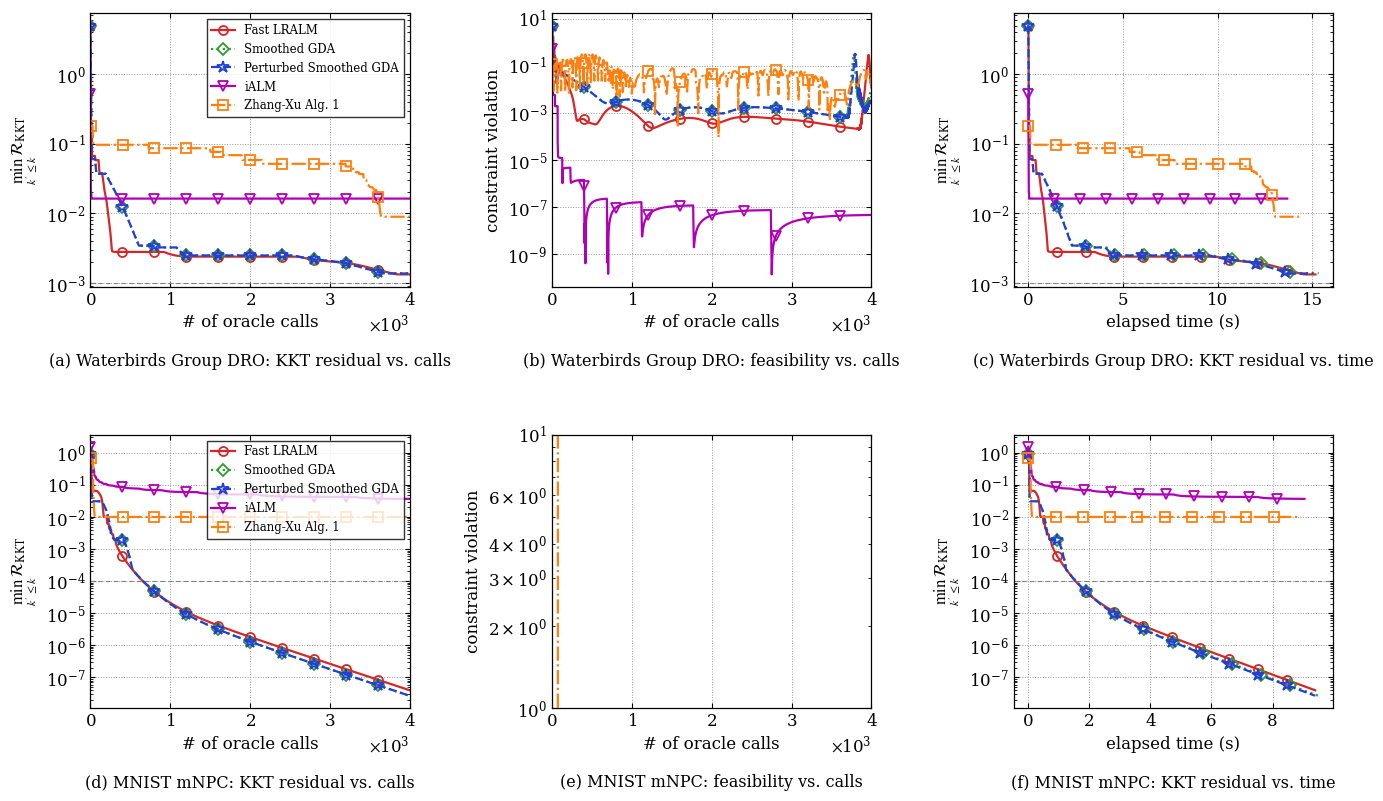

Saved fig_experiments.pdf & fig_experiments.png to /content/drive/MyDrive/3_DDLALM_exp


In [16]:
# 9. 作图：KKT 残差（vs oracle calls & vs elapsed time）与约束违反度
import matplotlib.pyplot as plt
from matplotlib.ticker import ScalarFormatter

plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Times", "DejaVu Serif"],
    "mathtext.fontset": "stix",
    "font.size": 12,
    "axes.linewidth": 0.9,
})

STYLE = {
    "Fast LRALM":             ("#d62728", "-",  "o"),
    "Smoothed GDA":           ("#2ca02c", ":",  "D"),
    "Perturbed Smoothed GDA": ("#1f3fd6", "--", "*"),
    "iALM":                   ("#b000b5", "-",  "v"),
    "Zhang-Xu Alg. 1":        ("#ff7f0e", "-.", "s"),
}

EXPS = [
    ("waterbirds_gdro_r3", "Waterbirds Group DRO", WB_EPS, WB_BUDGET),
    ("mnist_mnpc_r3",   "MNIST mNPC",           MN_EPS, MN_BUDGET),
]

fig, axes = plt.subplots(2, 3, figsize=(14.0, 8.2))
letters = iter("abcdef")

for i, (tag, title, eps, xmax) in enumerate(EXPS):
    D = np.load(os.path.join(OUT_DIR, f"{tag}.npz"))
    panels = [
        ("calls",   "kkt",  "# of oracle calls", r"$\min_{k'\leq k}\,\mathcal{R}_{\mathrm{KKT}}$", "KKT residual vs. calls"),
        ("calls",   "viol", "# of oracle calls", "constraint violation",                           "feasibility vs. calls"),
        ("elapsed", "kkt",  "elapsed time (s)",  r"$\min_{k'\leq k}\,\mathcal{R}_{\mathrm{KKT}}$", "KKT residual vs. time"),
    ]
    for j, (xkey, ykey, xlabel, ylabel, sub) in enumerate(panels):
        ax = axes[i, j]
        for name, (c, ls, mk) in STYLE.items():
            x = D[f"{name}|{xkey}"]
            y = D[f"{name}|{ykey}"]
            y = np.minimum.accumulate(np.nan_to_num(y, nan=np.inf)) if ykey == "kkt" else np.nan_to_num(y, nan=np.inf)
            y = np.clip(y, 1e-12, None)
            if xkey == "calls":
                keep = x <= xmax
                x, y = x[keep], y[keep]
            if len(x) == 0:
                continue
            idx = np.searchsorted(x, np.linspace(x[0], x[-1], 11)[:-1])
            ax.semilogy(x, y, color=c, ls=ls, lw=1.6, marker=mk,
                        ms=6.5 if mk != "*" else 9, mfc="none", mew=1.3,
                        markevery=list(np.unique(np.clip(idx, 0, len(x) - 1))), label=name)
        if ykey == "kkt":
            ax.axhline(eps, color="gray", lw=0.8, ls=(0, (4, 3)))
        if xkey == "calls":
            ax.set_xlim(0, xmax)
            fmt = ScalarFormatter(useMathText=True); fmt.set_powerlimits((0, 0))
            ax.xaxis.set_major_formatter(fmt)
        ax.grid(True, which="major", ls=":", lw=0.7, color="0.6")
        ax.tick_params(direction="in", top=True, right=True, which="both")
        ax.set_xlabel(xlabel)
        ax.set_ylabel(ylabel)
        if j == 0:
            ax.legend(fontsize=8.5, loc="upper right", frameon=True, fancybox=False, edgecolor="black")
        ax.text(0.5, -0.24, f"({next(letters)}) {title}: {sub}", transform=ax.transAxes,
                ha="center", va="top", fontsize=11.5)

fig.tight_layout(h_pad=3.2, w_pad=2.0)
fig.savefig(os.path.join(OUT_DIR, "fig_experiments_r3.pdf"), bbox_inches="tight")
fig.savefig(os.path.join(OUT_DIR, "fig_experiments_r3.png"), dpi=130, bbox_inches="tight")
plt.show()
print("Saved fig_experiments.pdf & fig_experiments.png to", OUT_DIR)